# 15. Does the Final Model Work Equally Well for Every Group of Students?

Notebook 14 reported one set of holdout numbers for all 885 students. An average can hide groups the model serves badly, which matters for an early-warning system: a group whose dropouts are consistently missed gets less outreach.

**Questions**
1. Does the final classifier (XGBoost, after Semester 1) perform differently across groups? (15.2)
2. Does the early-warning list (top 20% by risk, after Semester 1) reach the same share of dropouts in every group? Are its risk scores accurate within each group? (15.3)
3. Who are the dropouts the warning list misses, and why? (15.4)

**Groups:** gender, age at enrollment (≤20, 21–25, 26+), scholarship holder, daytime vs. evening attendance, debtor, and displaced (living away from home). These are the student characteristics an institution would most likely be asked about.

**Data:** the holdout predictions saved by notebook 14 (`data/processed/final_model_holdout_predictions.csv`). Nothing is retrained. Some groups are small (101 evening students, 19 dropouts among scholarship holders), so every number comes with a 95% bootstrap confidence interval.

## 15.0 Setup

In [1]:
import sys
from pathlib import Path

cwd = Path.cwd()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / "src" / "preprocessing.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the project root or its notebooks/ directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import warnings
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import f1_score

from src.plotting import OUTCOME_ORDER, OUTCOME_PALETTE
from src.preprocessing import load_data

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
N_BOOT = 2000
STAGE = "After Semester 1"
FIG_DIR = ROOT / "reports" / "figures"
OUT_DIR = ROOT / "data" / "processed"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pred_path = OUT_DIR / "final_model_holdout_predictions.csv"
if not pred_path.exists():
    raise FileNotFoundError("Run notebook 14 first: it saves final_model_holdout_predictions.csv.")
preds = pd.read_csv(pred_path, index_col="row")
df = load_data()
d = df.loc[preds.index].join(preds)

d["Predicted"] = d[f"Predicted ({STAGE})"]
d["Flagged"] = d[f"Flagged 20% ({STAGE})"].astype(bool)
d["Risk"] = d[f"Warning risk ({STAGE})"]
d["Is dropout"] = d["Actual"].eq("Dropout")

GROUPS = {
    "Gender": d["Gender"].map({0: "Female", 1: "Male"}),
    "Age at enrollment": pd.cut(d["Age at enrollment"], [0, 20, 25, 200], labels=["≤20", "21–25", "26+"]).astype(str),
    "Scholarship holder": d["Scholarship holder"].map({0: "No", 1: "Yes"}),
    "Attendance": d["Daytime/evening attendance"].map({1: "Daytime", 0: "Evening"}),
    "Debtor": d["Debtor"].map({0: "No", 1: "Yes"}),
    "Displaced": d["Displaced"].map({0: "No", 1: "Yes"}),
}
LEVEL_ORDER = {"Gender": ["Female", "Male"], "Age at enrollment": ["≤20", "21–25", "26+"],
               "Scholarship holder": ["No", "Yes"], "Attendance": ["Daytime", "Evening"],
               "Debtor": ["No", "Yes"], "Displaced": ["No", "Yes"]}
print(f"Holdout students: {len(d)} | dropouts: {int(d['Is dropout'].sum())} | "
      f"flagged (top 20%): {int(d['Flagged'].sum())}")

Holdout students: 885 | dropouts: 284 | flagged (top 20%): 176


## 15.1 Group sizes and dropout rates

Groups start from very different dropout rates, and that shapes everything below.

In [3]:
size_rows = []
for group, s in GROUPS.items():
    for level in LEVEL_ORDER[group]:
        m = s == level
        size_rows.append({"Group": group, "Level": level, "Students": int(m.sum()),
                          "Dropouts": int(d.loc[m, "Is dropout"].sum()),
                          "Dropout rate": d.loc[m, "Is dropout"].mean()})
sizes = pd.DataFrame(size_rows).set_index(["Group", "Level"])
display(sizes.style.format({"Dropout rate": "{:.1%}"}))

## 15.2 The final classifier by group

For each group: macro F1 and the recall of each outcome, with 95% bootstrap intervals (resampling students within the group).

Macro F1 is harder to compare across groups than recall, because it depends on each group's mix of outcomes; a group with very few Enrolled students can have a low macro F1 just from a handful of errors.

In [4]:
def boot(values_fn, idx, n_boot=N_BOOT, seed=RANDOM_STATE):
    """Point estimate and 95% bootstrap interval of values_fn over the students in idx."""
    rng = np.random.default_rng(seed)
    idx = np.asarray(idx)
    point = values_fn(idx)
    draws = [values_fn(rng.choice(idx, len(idx), replace=True)) for _ in range(n_boot)]
    lo, hi = np.nanpercentile(draws, [2.5, 97.5])
    return point, lo, hi


def class_recall(cls, rows):
    sub = d.loc[rows]
    truth = sub["Actual"] == cls
    return np.nan if truth.sum() == 0 else (sub.loc[truth, "Predicted"] == cls).mean()


CLASSIFIER_METRICS = {
    "Macro F1": lambda rows: f1_score(d.loc[rows, "Actual"], d.loc[rows, "Predicted"], average="macro"),
    **{f"{c} recall": partial(class_recall, c) for c in OUTCOME_ORDER},
}

clf_rows = []
for group, s in GROUPS.items():
    for level in LEVEL_ORDER[group]:
        rows = d.index[s == level]
        row = {"Group": group, "Level": level, "Students": len(rows)}
        for name, fn in CLASSIFIER_METRICS.items():
            point, lo, hi = boot(fn, rows)
            row[name], row[f"{name} CI"] = point, f"{lo:.2f}–{hi:.2f}"
        clf_rows.append(row)
by_group_clf = pd.DataFrame(clf_rows).set_index(["Group", "Level"])
overall_clf = {name: fn(d.index) for name, fn in CLASSIFIER_METRICS.items()}
print("Overall holdout: " + " | ".join(f"{k} {v:.3f}" for k, v in overall_clf.items()))
display(by_group_clf.round(3))

Overall holdout: Macro F1 0.667 | Dropout recall 0.648 | Enrolled recall 0.616 | Graduate recall 0.774


Students  Macro F1 Macro F1 CI  Dropout recall  \
Group              Level                                                     
Gender             Female        570     0.678   0.63–0.72           0.626   
                   Male          315     0.630   0.57–0.68           0.669   
Age at enrollment  ≤20           490     0.631   0.58–0.68           0.495   
                   21–25         180     0.654   0.58–0.72           0.638   
                   26+           215     0.681   0.61–0.75           0.790   
Scholarship holder No            680     0.654   0.62–0.69           0.660   
                   Yes           205     0.613   0.50–0.71           0.474   
Attendance         Daytime       784     0.667   0.63–0.70           0.630   
                   Evening       101     0.661   0.56–0.75           0.756   
Debtor             No            771     0.654   0.62–0.69           0.593   
                   Yes           114     0.677   0.57–0.77           0.841   
Displaced          No            401     0.691   0.64–0.73           0.725   
                   Yes           484     0.641   0.60–0.68           0.563   

                           Dropout recall CI  Enrolled recall  \
Group              Level                                        
Gender             Female          0.54–0.70            0.624   
                   Male            0.59–0.74            0.603   
Age at enrollment  ≤20             0.40–0.59            0.587   
                   21–25           0.51–0.76            0.744   
                   26+             0.71–0.86            0.536   
Scholarship holder No              0.60–0.72            0.662   
                   Yes             0.25–0.69            0.385   
Attendance         Daytime         0.57–0.69            0.625   
                   Evening         0.62–0.88            0.533   
Debtor             No              0.53–0.66            0.601   
                   Yes             0.74–0.93            0.714   
Displaced          No              0.65–0.79            0.634   
                   Yes             0.48–0.65            0.602   

                           Enrolled recall CI  Graduate recall  \
Group              Level                                         
Gender             Female           0.52–0.71            0.812   
                   Male             0.47–0.73            0.661   
Age at enrollment  ≤20              0.49–0.69            0.814   
                   21–25            0.60–0.88            0.639   
                   26+              0.34–0.72            0.765   
Scholarship holder No               0.58–0.74            0.684   
                   Yes              0.20–0.58            0.931   
Attendance         Daytime          0.55–0.70            0.778   
                   Evening          0.27–0.78            0.733   
Debtor             No               0.52–0.68            0.794   
                   Yes              0.50–0.90            0.500   
Displaced          No               0.52–0.74            0.757   
                   Yes              0.50–0.71            0.785   

                           Graduate recall CI  
Group              Level                       
Gender             Female           0.77–0.85  
                   Male             0.57–0.75  
Age at enrollment  ≤20              0.77–0.86  
                   21–25            0.53–0.74  
                   26+              0.66–0.86  
Scholarship holder No               0.63–0.74  
                   Yes              0.89–0.97  
Attendance         Daytime          0.74–0.82  
                   Evening          0.59–0.86  
Debtor             No               0.75–0.83  
                   Yes              0.32–0.68  
Displaced          No               0.69–0.82  
                   Yes              0.73–0.83

**Reading 15.2:**

- **Overall accuracy is similar across groups.** Macro F1 ranges from 0.61 to 0.69, and every group's confidence interval overlaps the overall 0.667.
- **The type of error is not similar.** Recall for each outcome follows how common that outcome is in the group:
  - **Dropout recall** is high where dropout is common (debtors 84%, students 26+ 79%, evening students 76%) and low where it's rare (students 20 or younger 50%, scholarship holders 47%).
  - **Graduate recall** goes the other way: scholarship holders 93%, debtors 50%.
- The model uses these characteristics as risk signals, so within a group it leans toward the outcome that is common there. A young scholarship holder who drops out is easy to mistake for a graduate, and a debtor who graduates is easy to mistake for a dropout.

## 15.3 The early-warning list by group

For the top-20% list from notebook 14 (cutoff set on training data), each group gets:

- **Share flagged:** how much of the group ends up on the list.
- **Dropouts reached:** the share of the group's dropouts who are on the list (recall). This is the "equal opportunity" check: do dropouts in every group have the same chance of being contacted?
- **Precision:** the share of flagged students in the group who do drop out.
- **Mean predicted risk vs. actual dropout rate:** whether the calibrated risk score is accurate *within* the group.

The gaps table compares each group's dropouts-reached rate with the other level(s) of the same characteristic, with a bootstrap interval for the difference.

In [5]:
def reached(rows):
    sub = d.loc[rows]
    return np.nan if sub["Is dropout"].sum() == 0 else sub.loc[sub["Is dropout"], "Flagged"].mean()


def precision(rows):
    sub = d.loc[rows]
    return np.nan if sub["Flagged"].sum() == 0 else sub.loc[sub["Flagged"], "Is dropout"].mean()


warn_rows = []
for group, s in GROUPS.items():
    for level in LEVEL_ORDER[group]:
        rows = d.index[s == level]
        r_pt, r_lo, r_hi = boot(reached, rows)
        p_pt, p_lo, p_hi = boot(precision, rows)
        warn_rows.append({"Group": group, "Level": level, "Students": len(rows),
                          "Dropouts": int(d.loc[rows, "Is dropout"].sum()),
                          "Share flagged": d.loc[rows, "Flagged"].mean(),
                          "Dropouts reached": r_pt, "Reached CI low": r_lo, "Reached CI high": r_hi,
                          "Precision": p_pt, "Precision CI": f"{p_lo:.2f}–{p_hi:.2f}",
                          "Mean predicted risk": d.loc[rows, "Risk"].mean(),
                          "Actual dropout rate": d.loc[rows, "Is dropout"].mean()})
by_group_warn = pd.DataFrame(warn_rows)
by_group_warn.to_csv(OUT_DIR / "subgroup_warning_holdout.csv", index=False)
print(f"Overall: share flagged {d['Flagged'].mean():.1%} | dropouts reached {reached(d.index):.1%} | "
      f"precision {precision(d.index):.1%}")
display(by_group_warn.set_index(["Group", "Level"]).style.format({
    "Share flagged": "{:.1%}", "Dropouts reached": "{:.1%}", "Reached CI low": "{:.1%}", "Reached CI high": "{:.1%}",
    "Precision": "{:.1%}", "Mean predicted risk": "{:.1%}", "Actual dropout rate": "{:.1%}"}))

Overall: share flagged 19.9% | dropouts reached 56.7% | precision 91.5%


In [6]:
rng = np.random.default_rng(RANDOM_STATE)
gap_rows = []
for group, s in GROUPS.items():
    levels = LEVEL_ORDER[group]
    ref = levels[0]
    for level in levels[1:]:
        a = d.index[(s == level) & d["Is dropout"]]
        b = d.index[(s == ref) & d["Is dropout"]]
        fa, fb = d.loc[a, "Flagged"].to_numpy(), d.loc[b, "Flagged"].to_numpy()
        diffs = [rng.choice(fa, len(fa)).mean() - rng.choice(fb, len(fb)).mean() for _ in range(N_BOOT)]
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        gap_rows.append({"Comparison": f"{group}: {level} vs. {ref}",
                         "Dropouts reached": f"{fa.mean():.0%} vs. {fb.mean():.0%}",
                         "Difference": fa.mean() - fb.mean(), "95% CI": f"{lo:+.0%} to {hi:+.0%}",
                         "CI excludes 0": (lo > 0) or (hi < 0)})
gaps = pd.DataFrame(gap_rows)
display(gaps.style.format({"Difference": "{:+.1%}"}))

,Comparison,Dropouts reached,Difference,95% CI,CI excludes 0
0,Gender: Male vs. Female,63% vs. 50%,+13.8%,+2% to +25%,True
1,Age at enrollment: 21–25 vs. ≤20,55% vs. 45%,+10.3%,-5% to +25%,False
2,Age at enrollment: 26+ vs. ≤20,68% vs. 45%,+23.2%,+11% to +36%,True
3,Scholarship holder: Yes vs. No,26% vs. 59%,-32.6%,-52% to -11%,True
4,Attendance: Evening vs. Daytime,63% vs. 56%,+7.9%,-8% to +24%,False
5,Debtor: Yes vs. No,78% vs. 51%,+27.1%,+16% to +39%,True
6,Displaced: Yes vs. No,50% vs. 63%,-13.5%,-25% to -1%,True


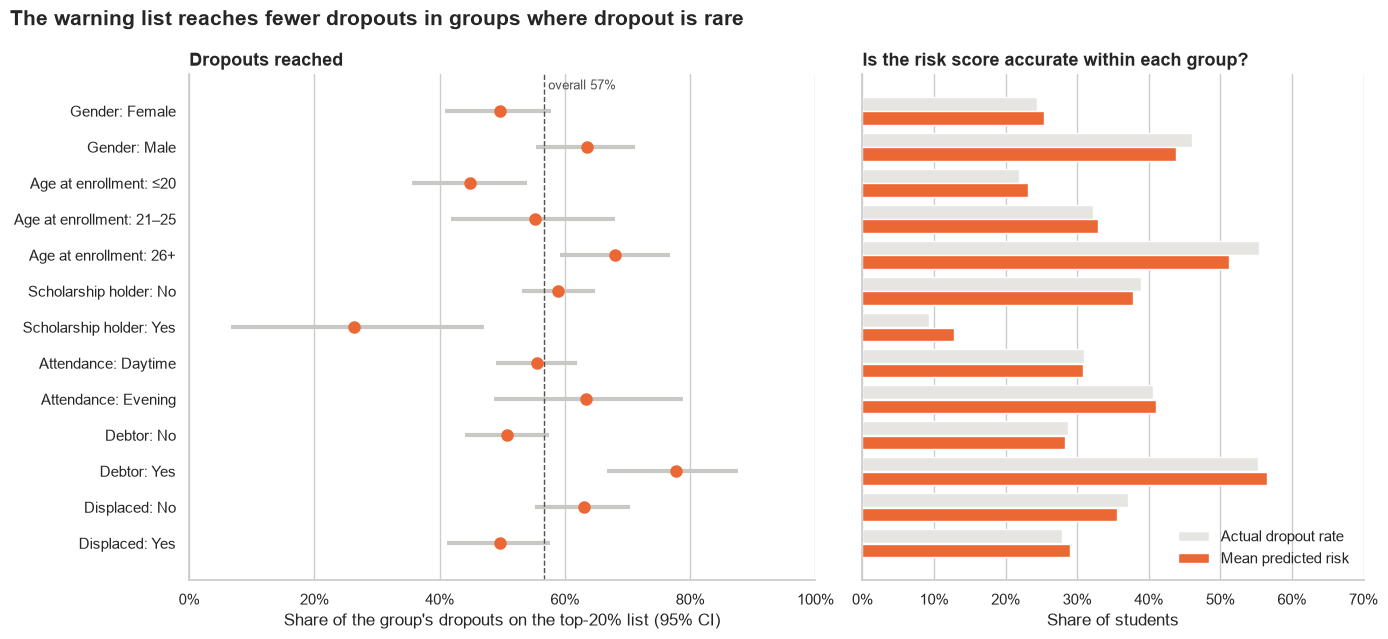

In [7]:
plot_df = by_group_warn.copy()
plot_df["Label"] = plot_df["Group"] + ": " + plot_df["Level"]
plot_df = plot_df.iloc[::-1].reset_index(drop=True)
overall_reached = reached(d.index)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True,
                         gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
ypos = np.arange(len(plot_df))
ax.errorbar(plot_df["Dropouts reached"], ypos,
            xerr=[plot_df["Dropouts reached"] - plot_df["Reached CI low"],
                  plot_df["Reached CI high"] - plot_df["Dropouts reached"]],
            fmt="o", color=OUTCOME_PALETTE["Dropout"], ecolor="#c9c8c4", elinewidth=3, capsize=0, ms=8)
ax.axvline(overall_reached, color="#52514e", ls="--", lw=1)
ax.text(overall_reached, len(plot_df) - 0.4, f" overall {overall_reached:.0%}", fontsize=9, color="#52514e")
ax.set_yticks(ypos, plot_df["Label"])
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Share of the group's dropouts on the top-20% list (95% CI)")
ax.set_title("Dropouts reached", loc="left", fontsize=13, fontweight="bold")

ax = axes[1]
ax.barh(ypos + 0.2, plot_df["Actual dropout rate"], height=0.38, color="#e6e5e1", label="Actual dropout rate")
ax.barh(ypos - 0.2, plot_df["Mean predicted risk"], height=0.38, color=OUTCOME_PALETTE["Dropout"],
        label="Mean predicted risk")
ax.set_xlim(0, 0.7)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Share of students")
ax.set_title("Is the risk score accurate within each group?", loc="left", fontsize=13, fontweight="bold")
ax.legend(loc="lower right", frameon=False)
for a in axes:
    a.grid(axis="y", visible=False)
fig.suptitle("The warning list reaches fewer dropouts in groups where dropout is rare", x=0.01, ha="left",
             fontsize=15, fontweight="bold")
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "subgroup_warning_reach.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading 15.3:**

- **The risk score is accurate within every group.** Mean predicted risk is within about 4 points of each group's actual dropout rate. Scholarship holders (12.8% predicted vs. 9.3% actual) are the largest gap, from only 19 dropouts.
- **Precision is about 90% in almost every group.** Students who get flagged really are at risk, whatever their group. Scholarship holders are the exception (62%, from only 8 flagged students).
- **But one cutoff for everyone reaches different shares of each group's dropouts:**
  - **Age:** 45% of dropouts aged 20 or younger vs. 68% of those 26+ (gap +23 points, CI +11 to +36)
  - **Gender:** 50% of female dropouts vs. 63% of male dropouts (+14 points, CI +2 to +25)
  - **Scholarship:** 26% of scholarship holders' dropouts vs. 59% of others' (−33 points, CI −52 to −11)
  - **Displaced:** 50% vs. 63% (−14 points, CI −25 to −1)
  - **Debtors:** 78% vs. 51% (+27 points)
  - Evening vs. daytime and ages 21–25 vs. ≤20 differences are not significant.
- **Why:** groups with a lower dropout rate get fewer flags, and their dropouts look less like typical dropouts (15.4). When groups have different dropout rates, a risk score can be accurate within each group *or* reach the same share of dropouts in each group, but not both.

**Options for a school:**

- Accept the gap: the list is accurate for everyone, and it follows actual risk.
- Contact more students: at 30% capacity every group's coverage rises.
- Set separate cutoffs per group to equalize reach. This would use characteristics like gender or age to decide who gets outreach, which raises legal and ethical questions.

This is a policy choice for the institution, not something the model can settle.

## 15.4 Who are the dropouts the list misses?

Comparing the dropouts on the top-20% list with the dropouts it misses shows *why* some groups are reached less often.

In [8]:
dropouts = d[d["Is dropout"]].copy()
dropouts["Sem 1 pass rate"] = (dropouts["Curricular units 1st sem (approved)"]
                               / dropouts["Curricular units 1st sem (enrolled)"].replace(0, np.nan)).clip(upper=1)
profile_cols = {
    "Curricular units 1st sem (approved)": "Sem 1 units passed",
    "Sem 1 pass rate": "Sem 1 pass rate",
    "Curricular units 1st sem (grade)": "Sem 1 grade average",
    "Tuition fees up to date": "Tuition up to date (share)",
    "Debtor": "Debtor (share)",
    "Scholarship holder": "Scholarship (share)",
    "Age at enrollment": "Age at enrollment",
    "Gender": "Male (share)",
    "Risk": "Predicted risk",
}
missed_profile = (dropouts.groupby(dropouts["Flagged"].map({True: "Reached", False: "Missed"}))[list(profile_cols)]
                  .mean().rename(columns=profile_cols).T[["Reached", "Missed"]])
missed_profile.loc["Students"] = dropouts["Flagged"].map({True: "Reached", False: "Missed"}).value_counts()
display(missed_profile.round(2))

missed = dropouts[~dropouts["Flagged"]]
on_track = missed["Sem 1 pass rate"] >= 0.8
print(f"Missed dropouts who passed at least 80% of their Semester 1 units: {int(on_track.sum())} of {len(missed)} "
      f"({on_track.mean():.0%}); {int(missed['Tuition fees up to date'].sum())} of {len(missed)} had tuition up to date.")

Flagged,Reached,Missed
Sem 1 units passed,1.29,4.07
Sem 1 pass rate,0.20,0.69
Sem 1 grade average,4.63,11.12
Tuition up to date (share),0.46,0.95
Debtor (share),0.30,0.11
Scholarship (share),0.03,0.11
Age at enrollment,27.31,24.46
Male (share),0.57,0.43
Predicted risk,0.91,0.34
Students,161.00,123.00


Missed dropouts who passed at least 80% of their Semester 1 units: 53 of 123 (43%); 117 of 123 had tuition up to date.


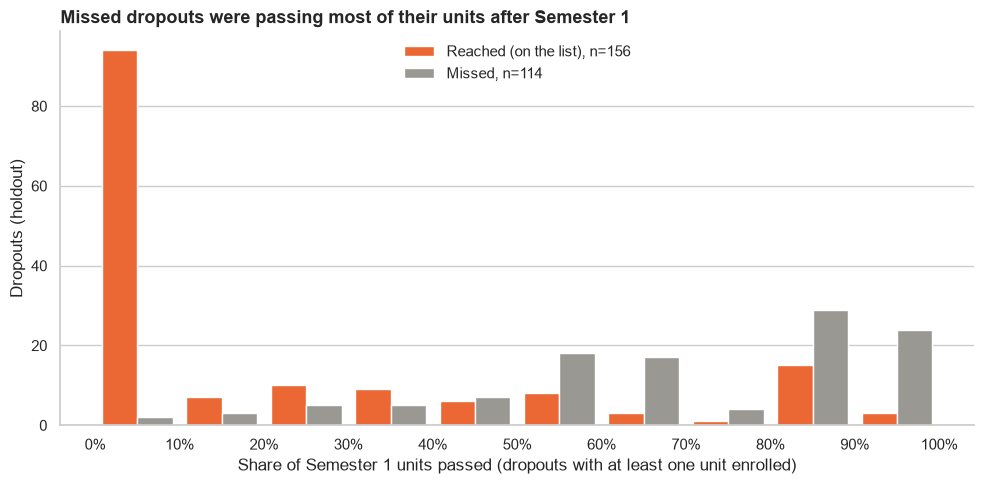

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.linspace(0, 1, 11)
centers = (bins[:-1] + bins[1:]) / 2
width = 0.042
for offset, (label, sub, color) in zip([-width / 2, width / 2], [
        ("Reached (on the list)", dropouts[dropouts["Flagged"]], OUTCOME_PALETTE["Dropout"]),
        ("Missed", dropouts[~dropouts["Flagged"]], "#9a9893")]):
    rates = sub["Sem 1 pass rate"].dropna()
    counts, _ = np.histogram(rates, bins=bins)
    ax.bar(centers + offset, counts, width=width, color=color, label=f"{label}, n={len(rates)}")
ax.set_xticks(bins)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Share of Semester 1 units passed (dropouts with at least one unit enrolled)")
ax.set_ylabel("Dropouts (holdout)")
ax.set_title("Missed dropouts were passing most of their units after Semester 1", loc="left",
             fontsize=13, fontweight="bold")
ax.legend(frameon=False, loc="upper center")
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "subgroup_missed_dropouts_pass_rate.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading 15.4: the missed dropouts look like students who are on track.**

| After Semester 1 | Dropouts reached (161) | Dropouts missed (123) |
|---|---|---|
| Units passed | 1.3 | 4.1 |
| Share of units passed | 20% | 69% |
| Grade average | 4.6 | 11.1 |
| Tuition up to date | 46% | 95% |
| Debtor | 30% | 11% |
| Scholarship holder | 3% | 11% |
| Age at enrollment | 27.3 | 24.5 |
| Predicted risk | 0.91 | 0.34 |

- **43% of the missed dropouts (53 of 123) passed at least 80% of their Semester 1 units**, and 95% had their tuition paid. Nothing in the data a school has after Semester 1 marks them as at risk.
- They are younger, less often male and more often scholarship holders, which is why those groups are reached less often in 15.3.
- **Conjecture:** these are "quiet" dropouts who leave for reasons the dataset doesn't record (personal or financial changes, transferring, or losing interest later in the program), rather than students who visibly struggle in Semester 1. It is the same limit we found for Enrolled students in notebook 09: the information that would separate them isn't in the data yet.
- Semester 2 data helps a little (Dropout recall rises from 65% to 69% with Full Data in notebook 14), but that comes too late for an early warning.

## 15.5 Answer

| Question | Finding |
|---|---|
| Does the final classifier work equally well across groups? | **Overall accuracy is similar** (macro F1 0.61–0.69, overlapping CIs), but **errors follow each group's dropout rate**: Dropout recall ranges from 47% (scholarship holders) to 84% (debtors). |
| Does the warning list treat groups equally? | The risk score is **accurate within every group** and precision is about 90% everywhere, but one cutoff **reaches fewer dropouts in low-dropout groups**: students 20 or younger (45% vs. 68% for 26+), women (50% vs. 63%), scholarship holders (26% vs. 59%). |
| Who gets missed? | **"Quiet" dropouts**: 43% of missed dropouts passed at least 80% of their Semester 1 units, and 95% had tuition paid. The data available after Semester 1 doesn't separate them from students who stay. |

**For the final presentation (limitations / "who does the model fail?" slide):**

- "The warning list is equally accurate for every group (about 9 in 10 flagged students do drop out), but it reaches fewer of the dropouts in groups where dropout is rare, such as younger students and scholarship holders."
- "The dropouts we miss look on track after Semester 1. They pass most of their units and pay tuition, so they likely leave for reasons the data doesn't capture."
- "Equalizing reach across groups would mean using characteristics like gender or age to decide who gets outreach. That's a policy decision for the institution."

**Limitations:**

- Some groups are small, so their intervals are wide (19 dropouts among scholarship holders, 41 among evening students).
- The groups overlap (older students are more often debtors and less often scholarship holders), so the gaps are not independent, and there's no intersectional analysis.
- One holdout set of 885 students.
- These are associations, not causes.

Outputs: `data/processed/subgroup_warning_holdout.csv`; figures `reports/figures/subgroup_warning_reach.png`, `subgroup_missed_dropouts_pass_rate.png`.